# Lab 3 — Làm quen với Hugging Face

Bài 1: tokenize và suy luận bằng mô hình SST-2 có sẵn. Bài 2: fine-tune DistilBERT trên IMDb, đánh giá và dự đoán câu mới. Dữ liệu và đầu vào là **tiếng Anh**.

**Môi trường thực nghiệm:** Python 3.14.0 trên CPU; phiên bản thư viện được ghi trong `requirements-run.txt` và cell kiểm tra môi trường bên dưới.

**Kết quả:** Trên 500 mẫu test IMDb, mô hình fine-tune đạt accuracy **82,40%** và F1 **83,46%** cho lớp POSITIVE. Phương pháp, kết quả và nhận xét được trình bày trong notebook và [báo cáo](report.md); minh chứng được lưu trong `results/`.

**Chạy lại:** Mở notebook từ thư mục `lab3/` cùng các file Python đi kèm và chọn kernel có đủ thư viện. Hướng dẫn cài đặt tại [README.md](README.md), hướng dẫn demo tại [demo.md](demo.md).

In [1]:
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
import json
import platform
import sys
import subprocess
from IPython.display import display, Image, Markdown

required_files = ['exercise1_sentiment.py', 'exercise2_finetune.py', 'predict.py']
if not all(Path(name).is_file() for name in required_files):
    raise FileNotFoundError('Hãy chạy notebook từ thư mục LAB_DEEP_LEARNING/lab3.')
print('Python:', sys.version)
print('Interpreter:', sys.executable)
print('Hệ điều hành:', platform.platform())
missing = []
for package in ['torch', 'transformers', 'datasets', 'accelerate', 'scikit-learn', 'matplotlib', 'numpy']:
    try:
        print(f'{package}: {version(package)}')
    except PackageNotFoundError:
        missing.append(package)
if missing:
    raise RuntimeError(f'Thiếu thư viện: {missing}. Cài requirements.txt bằng Python của kernel.')
import torch
print('CUDA khả dụng:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))


Python: 3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]
Interpreter: c:\Program Files\Python314\python.exe
Hệ điều hành: Windows-11-10.0.26300-SP0
torch: 2.13.0
transformers: 4.57.1
datasets: 4.4.1
accelerate: 1.11.0
scikit-learn: 1.7.2
matplotlib: 3.10.7
numpy: 2.3.4
CUDA khả dụng: False


## 1. Bài 1 — Tokenizer và mô hình có sẵn
Dùng `distilbert/distilbert-base-uncased-finetuned-sst-2-english`. Script in tokens, input IDs, nhãn và xác suất của nhãn được chọn, đồng thời lưu `outputs/exercise1.json`. Score không phải accuracy trên một tập dữ liệu.

In [2]:
from exercise1_sentiment import DEFAULT_TEXTS, run

texts = list(DEFAULT_TEXTS)
results = run(texts)
table = ['| Văn bản | Nhãn dự đoán | Score |', '|---|---|---|']
for row in results:
    text = row['text'].replace('|', '&#124;').replace('\n', ' ')
    table.append(f"| {text} | {row['label']} | {row['score']:.4f} |")
display(Markdown('\n'.join(table)))


[
  {
    "text": "I really enjoyed this movie!",
    "tokens": [
      "i",
      "really",
      "enjoyed",
      "this",
      "movie",
      "!"
    ],
    "input_ids": [
      101,
      1045,
      2428,
      5632,
      2023,
      3185,
      999,
      102
    ],
    "label": "POSITIVE",
    "score": 0.9998719692230225
  },
  {
    "text": "The movie was boring and disappointing.",
    "tokens": [
      "the",
      "movie",
      "was",
      "boring",
      "and",
      "disappointing",
      "."
    ],
    "input_ids": [
      101,
      1996,
      3185,
      2001,
      11771,
      1998,
      15640,
      1012,
      102
    ],
    "label": "NEGATIVE",
    "score": 0.9997933506965637
  },
  {
    "text": "The acting was excellent and the story was engaging.",
    "tokens": [
      "the",
      "acting",
      "was",
      "excellent",
      "and",
      "the",
      "story",
      "was",
      "engaging",
      "."
    ],
    "input_ids": [
      101,
      1996,
    

| Văn bản | Nhãn dự đoán | Score |
|---|---|---|
| I really enjoyed this movie! | POSITIVE | 0.9999 |
| The movie was boring and disappointing. | NEGATIVE | 0.9998 |
| The acting was excellent and the story was engaging. | POSITIVE | 0.9999 |
| I regret watching this movie because it was a waste of time. | NEGATIVE | 0.9998 |
| The soundtrack was beautiful and made the film memorable. | POSITIVE | 0.9999 |

### Quan sát bài 1

**Nhận xét của sinh viên:** Đã chạy mô hình trên **5 câu tiếng Anh**. Kết quả thực tế được lưu trong `results/exercise1.json`:

| Câu đầu vào | Nhãn dự đoán | Score |
|---|---|---|
| `I really enjoyed this movie!` | POSITIVE | 0.999872 |
| `The movie was boring and disappointing.` | NEGATIVE | 0.999793 |
| `The acting was excellent and the story was engaging.` | POSITIVE | 0.999879 |
| `I regret watching this movie because it was a waste of time.` | NEGATIVE | 0.999779 |
| `The soundtrack was beautiful and made the film memorable.` | POSITIVE | 0.999887 |

Mô hình gán 3 câu nhãn POSITIVE và 2 câu nhãn NEGATIVE. Các câu 1, 3 và 5 diễn tả sự yêu thích hoặc khen diễn xuất, nội dung, âm nhạc; các câu 2 và 4 diễn tả sự nhàm chán, thất vọng hoặc hối tiếc khi xem phim. Cả năm nhãn dự đoán đều phù hợp với ý nghĩa của các câu minh họa.

**Token và ID thực tế:**

- Câu 1: `['i', 'really', 'enjoyed', 'this', 'movie', '!']`; input IDs: `[101, 1045, 2428, 5632, 2023, 3185, 999, 102]`.
- Câu 2: `['the', 'movie', 'was', 'boring', 'and', 'disappointing', '.']`; input IDs: `[101, 1996, 3185, 2001, 11771, 1998, 15640, 1012, 102]`.
- Câu 3: `['the', 'acting', 'was', 'excellent', 'and', 'the', 'story', 'was', 'engaging', '.']`; input IDs: `[101, 1996, 3772, 2001, 6581, 1998, 1996, 2466, 2001, 11973, 1012, 102]`.
- Câu 4: `['i', 'regret', 'watching', 'this', 'movie', 'because', 'it', 'was', 'a', 'waste', 'of', 'time', '.']`; input IDs: `[101, 1045, 9038, 3666, 2023, 3185, 2138, 2009, 2001, 1037, 5949, 1997, 2051, 1012, 102]`.
- Câu 5: `['the', 'soundtrack', 'was', 'beautiful', 'and', 'made', 'the', 'film', 'memorable', '.']`; input IDs: `[101, 1996, 6050, 2001, 3376, 1998, 2081, 1996, 2143, 13432, 1012, 102]`.

Tokenizer chuyển chữ về dạng thường và tách dấu câu thành token riêng. Từ `movie` có ID `3185` trong các câu có từ này; ID `101` và `102` là token đặc biệt ở đầu và cuối chuỗi đầu vào.

Score là xác suất softmax của nhãn được chọn, không phải accuracy trên tập dữ liệu. Năm câu minh họa chưa đủ để kết luận chất lượng tổng quát của mô hình.

## 2. Bài 2 — Cấu hình thực nghiệm
Bắt đầu từ `distilbert/distilbert-base-uncased` với đầu phân loại hai nhãn: `0 = NEGATIVE`, `1 = POSITIVE`. Train và validation lấy từ các phần không trùng nhau của tập train IMDb đã shuffle; test lấy từ tập test gốc, chỉ dùng đánh giá cuối.

Mặc định `MODE = 'report'`: 2.000 train, 500 validation, 500 test, 2 epoch. Đổi thành `'demo'` để thử nhanh 64/32/32 mẫu, 1 epoch. Hai chế độ lưu ở hai thư mục khác nhau. Kết quả demo chỉ kiểm tra luồng.

Script dùng learning rate `2e-5`, weight decay `0.01`, padding theo batch, đánh giá/lưu mỗi epoch và chọn checkpoint theo validation F1.

In [3]:
MODE = 'report'  # Đổi thành 'demo' để thử nhanh.
USE_CPU = False  # True để ép CPU; nếu không có CUDA, script tự dùng CPU.
BATCH_SIZE = 8
MAX_LENGTH = 128
SEED = 42

profiles = {
    'report': {'train_size': 2000, 'val_size': 500, 'test_size': 500, 'epochs': 2, 'output_dir': 'outputs/finetune'},
    'demo': {'train_size': 64, 'val_size': 32, 'test_size': 32, 'epochs': 1, 'output_dir': 'outputs/demo'},
}
if MODE not in profiles:
    raise ValueError('MODE phải là report hoặc demo.')
config = {**profiles[MODE], 'batch_size': BATCH_SIZE, 'max_length': MAX_LENGTH, 'seed': SEED}
out = Path(config['output_dir'])
print('Chế độ:', MODE)
print(json.dumps(config, indent=2))
print('Thiết bị:', 'cuda' if torch.cuda.is_available() and not USE_CPU else 'cpu')


Chế độ: report
{
  "train_size": 2000,
  "val_size": 500,
  "test_size": 500,
  "epochs": 2,
  "output_dir": "outputs/finetune",
  "batch_size": 8,
  "max_length": 128,
  "seed": 42
}
Thiết bị: cpu


## 3. Fine-tune và đánh giá test
Cell gọi script bằng đúng Python của kernel. Huấn luyện có thể chạy lâu trên CPU. Chạy lại với cùng thư mục đầu ra có thể ghi đè kết quả. Nếu đã có kết quả cần xem, có thể bỏ qua cell này sau khi chạy các cell import/cấu hình.

In [4]:
command = [sys.executable, 'exercise2_finetune.py']
for key, value in config.items():
    command.extend(['--' + key.replace('_', '-'), str(value)])
if USE_CPU:
    command.append('--cpu')
print('Lệnh:', subprocess.list2cmdline(command))
with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                      text=True, encoding='utf-8', errors='replace') as process:
    for line in process.stdout:
        print(line, end='', flush=True)
    return_code = process.wait()
if return_code:
    raise subprocess.CalledProcessError(return_code, command)


Lệnh: "c:\Program Files\Python314\python.exe" exercise2_finetune.py --train-size 2000 --val-size 500 --test-size 500 --epochs 2 --output-dir outputs/finetune --batch-size 8 --max-length 128 --seed 42


CompletedProcess(args=['c:\\Program Files\\Python314\\python.exe', 'exercise2_finetune.py', '--train-size', '2000', '--val-size', '500', '--test-size', '500', '--epochs', '2', '--output-dir', 'outputs/finetune', '--batch-size', '8', '--max-length', '128', '--seed', '42'], returncode=0)

## 4. Kết quả thực tế
Đọc cấu hình đã lưu cùng kết quả để xác định đúng lần chạy. Precision/recall/F1 trong `metrics.json` tính với POSITIVE là lớp dương. Không đổi MODE rồi lấy nhầm số liệu giữa demo và báo cáo.

In [5]:
expected = ['config.json', 'metrics.json', 'classification_report.txt', 'confusion_matrix.png', 'loss_curve.png', 'training_history.json']
missing_outputs = [name for name in expected if not (out / name).is_file()]
if missing_outputs:
    raise FileNotFoundError(f'Thiếu kết quả trong {out}: {missing_outputs}. Hoàn thành huấn luyện hoặc kiểm tra MODE.')
saved_config = json.loads((out / 'config.json').read_text(encoding='utf-8'))
metrics = json.loads((out / 'metrics.json').read_text(encoding='utf-8'))
print('Cấu hình thực tế đã lưu:')
print(json.dumps(saved_config, indent=2))
if any(saved_config.get(key) != value for key, value in config.items()) or saved_config.get('cpu') != USE_CPU:
    print('LƯU Ý: cấu hình đã lưu khác cell hiện tại. Số liệu bên dưới thuộc cấu hình đã lưu.')
table = ['| Chỉ số test | Giá trị thực tế |', '|---|---|']
for key in ['test_loss', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1']:
    table.append(f'| {key} | {metrics[key]:.4f} |')
display(Markdown('\n'.join(table)))
print((out / 'classification_report.txt').read_text(encoding='utf-8'))


Cấu hình thực tế đã lưu:
{
  "train_size": 2000,
  "val_size": 500,
  "test_size": 500,
  "epochs": 2.0,
  "batch_size": 8,
  "max_length": 128,
  "seed": 42,
  "output_dir": "outputs/finetune",
  "cpu": false
}


| Chỉ số test | Giá trị thực tế |
|---|---|
| test_loss | 0.4157 |
| test_accuracy | 0.8240 |
| test_precision | 0.7762 |
| test_recall | 0.9024 |
| test_f1 | 0.8346 |

              precision    recall  f1-score   support

    NEGATIVE       0.89      0.75      0.81       254
    POSITIVE       0.78      0.90      0.83       246

    accuracy                           0.82       500
   macro avg       0.83      0.83      0.82       500
weighted avg       0.83      0.82      0.82       500



### Confusion matrix và đường loss
Ma trận: hàng là nhãn thật, cột là nhãn dự đoán. Train loss được log theo bước, validation loss theo epoch. Chế độ một epoch có ít điểm nên chưa đủ để nhận xét xu hướng.

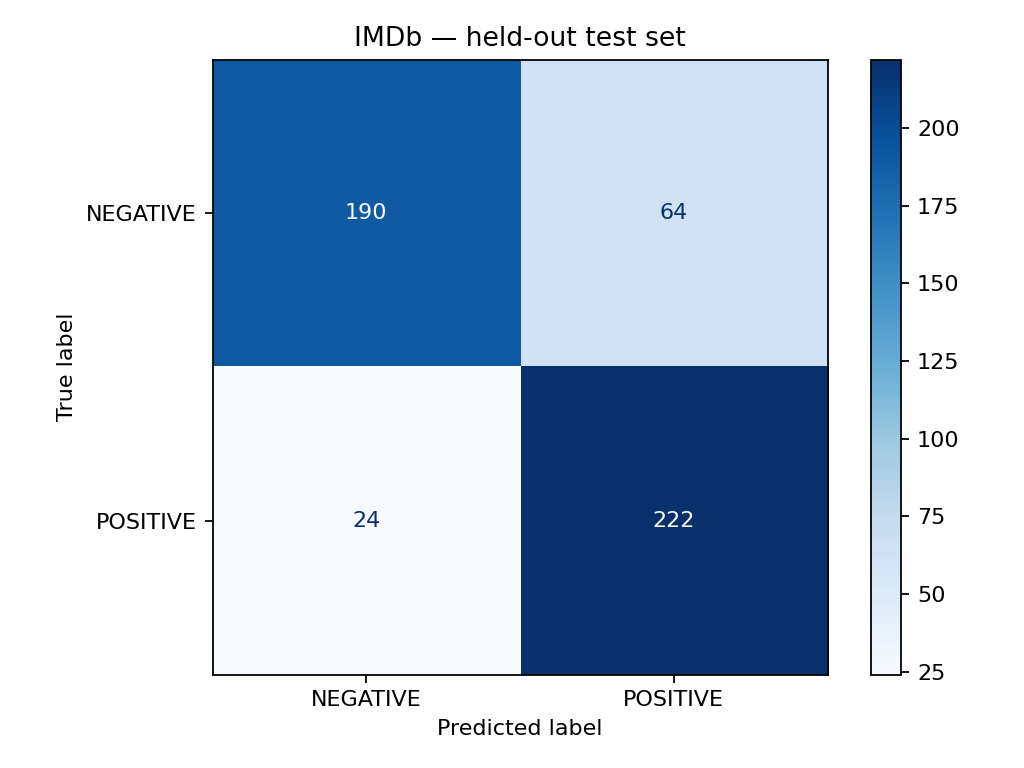

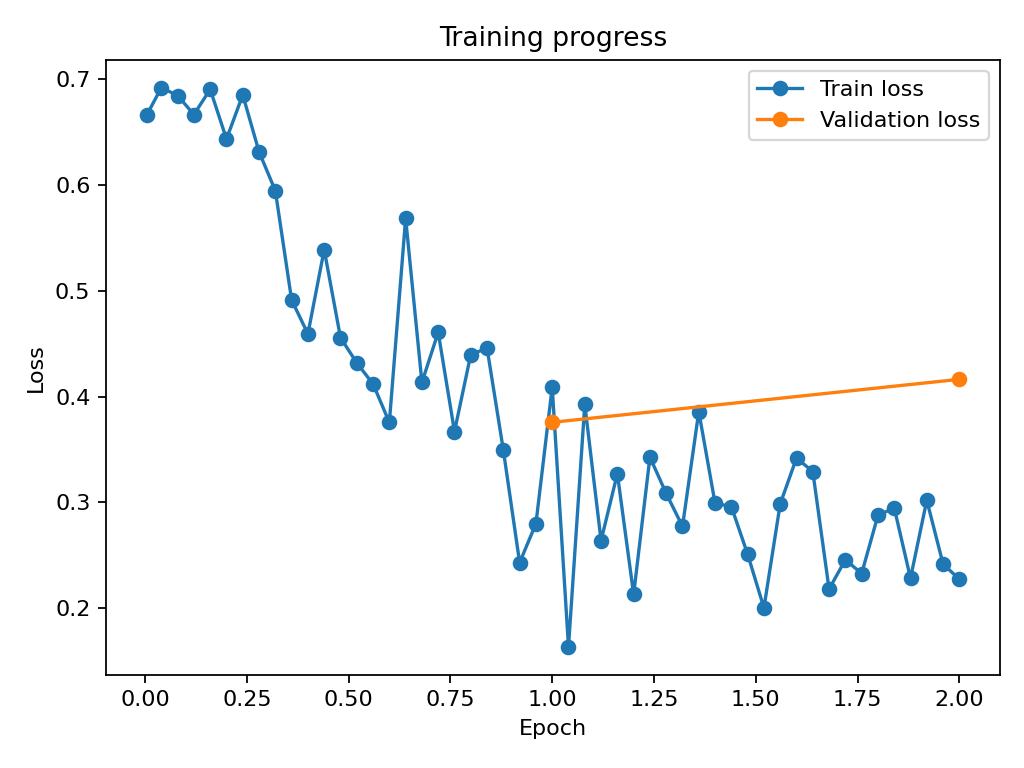

Đánh giá validation theo epoch:
{'epoch': 1.0, 'eval_loss': 0.3756883144378662, 'eval_accuracy': 0.842, 'eval_f1': 0.851782363977486}
{'epoch': 2.0, 'eval_loss': 0.4162949323654175, 'eval_accuracy': 0.838, 'eval_f1': 0.8396039603960396}


In [6]:
display(Image(filename=str(out / 'confusion_matrix.png')))
display(Image(filename=str(out / 'loss_curve.png')))
history = json.loads((out / 'training_history.json').read_text(encoding='utf-8'))
print('Đánh giá validation theo epoch:')
for entry in history:
    if 'eval_loss' in entry:
        print({key: entry[key] for key in ['epoch', 'eval_loss', 'eval_accuracy', 'eval_f1'] if key in entry})


## 5. Dự đoán câu mới bằng mô hình đã lưu
Dùng mô hình trong đúng thư mục của chế độ đang chọn. Nhãn và score bên dưới là kết quả suy luận thực tế khi chạy cell.

In [7]:
model_dir = out / 'model'
if not (model_dir / 'config.json').is_file():
    raise FileNotFoundError(f'Chưa có mô hình trong {model_dir}. Hoàn thành huấn luyện trước.')
new_texts = ['The acting was excellent!', 'I regret watching this movie.']
prediction_command = [sys.executable, 'predict.py', '--model', str(model_dir),
                      '--output', str(out / 'predictions.json'), '--text', *new_texts]
if USE_CPU:
    prediction_command.append('--cpu')
completed = subprocess.run(prediction_command, capture_output=True, text=True,
                           encoding='utf-8', errors='replace')
print(completed.stdout, end='')
if completed.stderr:
    print(completed.stderr, end='')
completed.check_returncode()


The acting was excellent! -> POSITIVE (0.9113)
I regret watching this movie. -> NEGATIVE (0.7464)


## 6. Nhận xét sau thực nghiệm

1. **Cấu hình và môi trường:** Python 3.14.0, Windows 11, CPU (`CUDA khả dụng: False`). Dùng 2.000 train / 500 validation / 500 test, batch 8, max length 128, seed 42, 2 epoch. Trainer ghi thời gian huấn luyện **1050.06 giây**, khoảng **17 phút 30 giây**; thời gian test **27.38 giây**. Các thời gian này không bao gồm toàn bộ bước tải và chuẩn bị dữ liệu.
2. **Bài 1:** Đã suy luận trên 5 câu tiếng Anh, thu được 3 nhãn POSITIVE và 2 nhãn NEGATIVE; chi tiết nhãn, score và token/ID ở phần Quan sát bài 1. Score là xác suất nhãn, không phải accuracy toàn bộ mô hình.
3. **Bài 2:** Trên 500 mẫu test, accuracy **82.40%**, precision **77.62%**, recall **90.24%**, F1 **83.46%** với POSITIVE là lớp dương; test loss **0.415744**. Có 412 dự đoán đúng và 88 dự đoán sai.
4. **Lớp dễ nhầm:** Confusion matrix là `[[190, 64], [24, 222]]` (hàng: nhãn thật; cột: dự đoán). Có 64 review tiêu cực bị đoán thành tích cực, so với 24 lỗi theo chiều ngược lại. Recall NEGATIVE chỉ khoảng 74,80%, thấp hơn recall POSITIVE 90,24%; precision POSITIVE là 77,62%.
5. **Loss và checkpoint:** Train loss có xu hướng giảm nhưng vẫn dao động. Validation loss tăng từ 0.375688 ở epoch 1 lên 0.416295 ở epoch 2; validation F1 giảm từ 0.851782 xuống 0.839604. Đây là dấu hiệu mô hình khớp tập train hơn nhưng khả năng tổng quát hóa không cải thiện ở epoch 2. Chỉ có hai mốc validation nên chưa đủ kết luận xu hướng dài hạn. Checkpoint tốt nhất là **epoch 1, step 250**; script nạp lại checkpoint này trước khi đánh giá test.
6. **Dự đoán câu mới:** Đã kiểm tra lại bằng mô hình được lưu, không huấn luyện lại:

| Câu mới | Nhãn thực tế | Score |
|---|---|---|
| `The acting was excellent!` | POSITIVE | 0.911281 |
| `I regret watching this movie.` | NEGATIVE | 0.746396 |

Hai nhãn phù hợp với ý nghĩa các câu. Đây là ví dụ minh họa, không phải tập đánh giá bổ sung. Hiện chưa lưu văn bản của 88 review test bị dự đoán sai, nên không có cơ sở nêu một câu sai cụ thể.

**Hạn chế:** Kết quả chỉ áp dụng cho 500 mẫu test đã chọn, chưa đại diện toàn bộ IMDb hay tiếng Việt. Mô hình chỉ có hai nhãn; cắt ở 128 token có thể bỏ mất ngữ cảnh cuối review. Chưa có thí nghiệm nhiều seed hoặc so sánh cấu hình để khẳng định ảnh hưởng nhân quả của số mẫu/số epoch.

**Minh chứng:** Thư mục `results/` lưu bản sao chỉ số, cấu hình, lịch sử, hai biểu đồ và kết quả dự đoán. Các output đã chạy trong notebook được giữ lại.
